# Comparación de candidatos MOPSO

La función compara los tres archivos de resultados (`rmse`, `nasa` y `both`) para un dataset. Usa métricas `test_*`, convierte el NASA sumativo a promedio por motor para mostrarlo en escala logarítmica y mantiene el valor sumativo medido para aplicar los filtros NASA. Los intervalos bootstrap del 95% se muestran en la gráfica como líneas horizontales y verticales.

In [32]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D


OBJECTIVES = ('rmse', 'nasa', 'both')
OBJECTIVE_COLORS = {
    'rmse': '#2878B5',
    'nasa': '#E07A2D',
    'both': '#3A923A',
}


def _required_number(mapping, key, context):
    if key not in mapping:
        raise KeyError(f'Falta el campo {key!r} en {context}.')
    value = float(mapping[key])
    if not np.isfinite(value):
        raise ValueError(f'El campo {key!r} no es finito en {context}.')
    return value


def compare_candidate_results(
    dataset_name,
    results_dir='mopso_results',
    test_rul_path=None,
    min_parameters=None,
    max_parameters=None,
    min_rmse=None,
    max_rmse=None,
    min_nasa=None,
    max_nasa=None,
):
    """Grafica candidatos; filtros NASA usan el promedio por motor."""
    dataset_name = str(dataset_name).strip().upper()
    supported_datasets = {f'FD00{i}' for i in range(1, 5)}
    if dataset_name not in supported_datasets:
        choices = ', '.join(sorted(supported_datasets))
        raise ValueError(
            f'Dataset no admitido: {dataset_name!r}. Use uno de: {choices}.'
        )

    filter_bounds = {
        'parameter_count': (min_parameters, max_parameters),
        'rmse': (min_rmse, max_rmse),
        'nasa_score': (min_nasa, max_nasa),
    }
    normalized_bounds = {}
    for metric, (minimum, maximum) in filter_bounds.items():
        converted = []
        for label, value in (('mínimo', minimum), ('máximo', maximum)):
            if value is None:
                converted.append(None)
                continue
            number = float(value)
            if not np.isfinite(number):
                raise ValueError(f'El {label} de {metric} debe ser finito.')
            converted.append(number)
        if converted[0] is not None and converted[1] is not None and converted[0] > converted[1]:
            raise ValueError(f'El mínimo de {metric} no puede superar el máximo.')
        normalized_bounds[metric] = tuple(converted)

    results_dir = Path(results_dir)
    if test_rul_path is None:
        rul_filename = f'RUL_{dataset_name}.txt'
        rul_candidates = (
            Path('data') / 'CMAPSSData' / rul_filename,
            Path('data') / 'backup_root_files' / rul_filename,
            results_dir.parent / 'data' / 'CMAPSSData' / rul_filename,
            results_dir.parent / 'data' / 'backup_root_files' / rul_filename,
        )
        test_rul_path = next(
            (path for path in rul_candidates if path.is_file()), None
        )
        if test_rul_path is None:
            searched = ', '.join(str(path) for path in rul_candidates)
            raise FileNotFoundError(
                f'No se encontró {rul_filename}; rutas comprobadas: {searched}. '
                'Pase test_rul_path explícitamente.'
            )
    else:
        test_rul_path = Path(test_rul_path)
        if not test_rul_path.is_file():
            raise FileNotFoundError(f'No se encontró {test_rul_path}.')

    with test_rul_path.open('r', encoding='utf-8') as rul_file:
        test_engine_count = sum(1 for line in rul_file if line.strip())
    if test_engine_count <= 0:
        raise ValueError(f'No se encontraron motores en {test_rul_path}.')

    records = []
    for objective in OBJECTIVES:
        json_path = results_dir / (
            f'{dataset_name}_mopso_final_candidates_v6_{objective}.json'
        )
        if not json_path.is_file():
            raise FileNotFoundError(
                f'No se encontró {json_path}. Pase la carpeta de resultados '
                "con results_dir si no es 'mopso_results'."
            )

        with json_path.open('r', encoding='utf-8') as json_file:
            package = json.load(json_file)
        if package.get('dataset') != dataset_name:
            raise ValueError(
                f'El dataset declarado en {json_path} no coincide con '
                f'{dataset_name}.'
            )
        if package.get('objective') != objective:
            raise ValueError(
                f'El objetivo declarado en {json_path} no coincide con '
                f'{objective}.'
            )

        candidates = package.get('candidates')
        if not isinstance(candidates, list) or not candidates:
            raise ValueError(f'No hay candidatos en {json_path}.')

        for candidate in candidates:
            candidate_id = candidate.get('candidate_id')
            architecture = candidate.get('architecture', {})
            hidden_sizes = architecture.get('hidden_sizes')
            metrics = candidate.get('test_results', {})
            context = f'{json_path.name}, candidato {candidate_id!r}'
            if not candidate_id:
                raise ValueError(f'Falta candidate_id en {context}.')
            if not isinstance(hidden_sizes, list):
                raise ValueError(f'Falta architecture.hidden_sizes en {context}.')
            if not isinstance(metrics, dict):
                raise ValueError(f'test_results no es válido en {context}.')

            parameter_count = int(
                _required_number(candidate, 'parameter_count', context)
            )
            if parameter_count <= 0:
                raise ValueError(f'parameter_count debe ser positivo en {context}.')

            rmse = _required_number(metrics, 'test_rmse', context)
            nasa = _required_number(metrics, 'test_nasa', context)
            rmse_low = _required_number(metrics, 'test_rmse_ci95_lower', context)
            rmse_high = _required_number(metrics, 'test_rmse_ci95_upper', context)
            nasa_low = _required_number(metrics, 'test_nasa_ci95_lower', context)
            nasa_high = _required_number(metrics, 'test_nasa_ci95_upper', context)
            if rmse_low > rmse_high or nasa_low > nasa_high:
                raise ValueError(f'Los límites de confianza están invertidos en {context}.')
            if nasa_low <= 0:
                raise ValueError(
                    f'El límite inferior del IC NASA debe ser positivo para '
                    f'usar escala logarítmica en {context}.'
                )

            records.append({
                'objective': objective,
                'candidate_id': str(candidate_id),
                'hidden_sizes': tuple(int(size) for size in hidden_sizes),
                'parameter_count': parameter_count,
                'rmse': rmse,
                'rmse_low': rmse_low,
                'rmse_high': rmse_high,
                'nasa_score': nasa,
                'nasa': nasa / test_engine_count,
                'nasa_low': nasa_low / test_engine_count,
                'nasa_high': nasa_high / test_engine_count,
                'selected_winner': bool(candidate.get('selected_winner', False)),
            })

    records = [
        record for record in records
        if all(
            (minimum is None or record[metric] >= minimum)
            and (maximum is None or record[metric] <= maximum)
            for metric, (minimum, maximum) in normalized_bounds.items()
        )
    ]
    if not records:
        raise ValueError(
            'Ningún candidato cumple los límites solicitados; amplíe o quite filtros.'
        )

    parameter_logs = np.log10([record['parameter_count'] for record in records])
    log_min = float(parameter_logs.min())
    log_range = float(parameter_logs.max() - log_min)
    bubble_areas = [
        70.0 + 230.0 * ((value - log_min) / log_range if log_range else 0.5)
        for value in parameter_logs
    ]
    rmse_values = np.array([record['rmse'] for record in records])
    nasa_values = np.array([record['nasa'] for record in records])
    x_span = max(float(np.ptp(rmse_values)), float(np.max(np.abs(rmse_values))) * 0.05, 1.0)
    y_span = max(float(np.ptp(nasa_values)), float(np.max(np.abs(nasa_values))) * 0.05, 1.0)
    cap_x = x_span * 0.006
    cap_y = y_span * 0.006

    fig, ax = plt.subplots(figsize=(13, 8))
    annotation_offsets = ((6, 6), (6, -13), (-6, 8), (-6, -13))
    for index, (record, bubble_area) in enumerate(zip(records, bubble_areas)):
        color = OBJECTIVE_COLORS[record['objective']]
        x, y = record['rmse'], record['nasa']
        ax.hlines(
            y, record['rmse_low'], record['rmse_high'],
            color=color, alpha=0.65, linewidth=1.2, zorder=1,
        )
        ax.vlines(
            [record['rmse_low'], record['rmse_high']], y - cap_y, y + cap_y,
            color=color, alpha=0.65, linewidth=1.2, zorder=1,
        )
        ax.vlines(
            x, record['nasa_low'], record['nasa_high'],
            color=color, alpha=0.65, linewidth=1.2, zorder=1,
        )
        ax.hlines(
            [record['nasa_low'], record['nasa_high']], x - cap_x, x + cap_x,
            color=color, alpha=0.65, linewidth=1.2, zorder=1,
        )
        ax.scatter(
            x, y, s=bubble_area, color=color, alpha=0.72,
            edgecolors='white', linewidths=0.9, zorder=2,
        )
        if record['selected_winner']:
            ax.scatter(
                x, y, s=55, marker='*', color=color,
                edgecolors='black', linewidths=0.6, zorder=4,
            )

        offset = annotation_offsets[index % len(annotation_offsets)]
        ax.annotate(
            f"{record['objective']} {record['hidden_sizes']}",
            (x, y), xytext=offset, textcoords='offset points',
            ha='left' if offset[0] > 0 else 'right',
            va='bottom' if offset[1] > 0 else 'top', fontsize=7,
            bbox={'boxstyle': 'round,pad=0.15', 'fc': 'white', 'ec': 'none', 'alpha': 0.72},
            zorder=5,
        )

    method_handles = [
        Line2D(
            [], [], marker='o', linestyle='none', markersize=8,
            markerfacecolor=OBJECTIVE_COLORS[objective], markeredgecolor='white',
            label=objective,
        )
        for objective in OBJECTIVES
    ]
    objective_legend = ax.legend(
        handles=method_handles, title='Optimización', loc='upper left',
        bbox_to_anchor=(1.02, 1.0),
    )
    ax.add_artist(objective_legend)

    unique_counts = sorted({record['parameter_count'] for record in records})
    if len(unique_counts) > 3:
        indices = np.unique(np.round(np.linspace(0, len(unique_counts) - 1, 3)).astype(int))
        size_counts = [unique_counts[index] for index in indices]
    else:
        size_counts = unique_counts
    size_handles = []
    for count in size_counts:
        log_count = np.log10(count)
        fraction = (log_count - log_min) / log_range if log_range else 0.5
        area = 70.0 + 230.0 * fraction
        size_handles.append(
            Line2D(
                [], [], marker='o', linestyle='none', markersize=np.sqrt(area),
                markerfacecolor='none', markeredgecolor='0.4',
                label=f'{count:,}',
            )
        )
    size_legend = ax.legend(
        handles=size_handles, title='Parámetros', loc='upper left',
        bbox_to_anchor=(1.02, 0.68), labelspacing=1.2,
    )
    ax.add_artist(size_legend)
    winner_handle = Line2D(
        [], [], marker='*', linestyle='none', markersize=8,
        markerfacecolor='gold', markeredgecolor='black', label='Seleccionado',
    )
    ax.legend(
        handles=[winner_handle], loc='upper left', bbox_to_anchor=(1.02, 0.27),
        frameon=False,
    )

    ax.set_title(
        f'Comparación de candidatos — {dataset_name}'
    )
    ax.set_xlabel('RMSE de test')
    ax.set_yscale('log')
    ax.set_ylabel('NASA score medio por motor (escala logarítmica)')
    ax.grid(True, linestyle='--', alpha=0.3)
    fig.tight_layout(rect=(0, 0, 0.78, 1))
    plt.show()
    return fig, ax

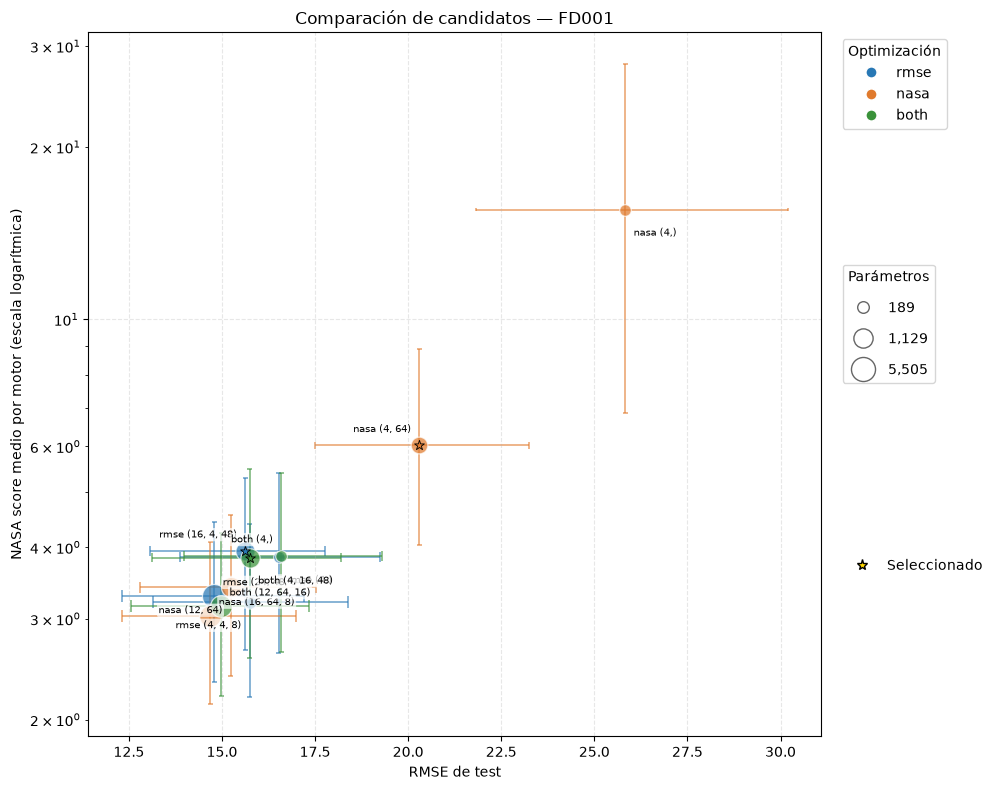

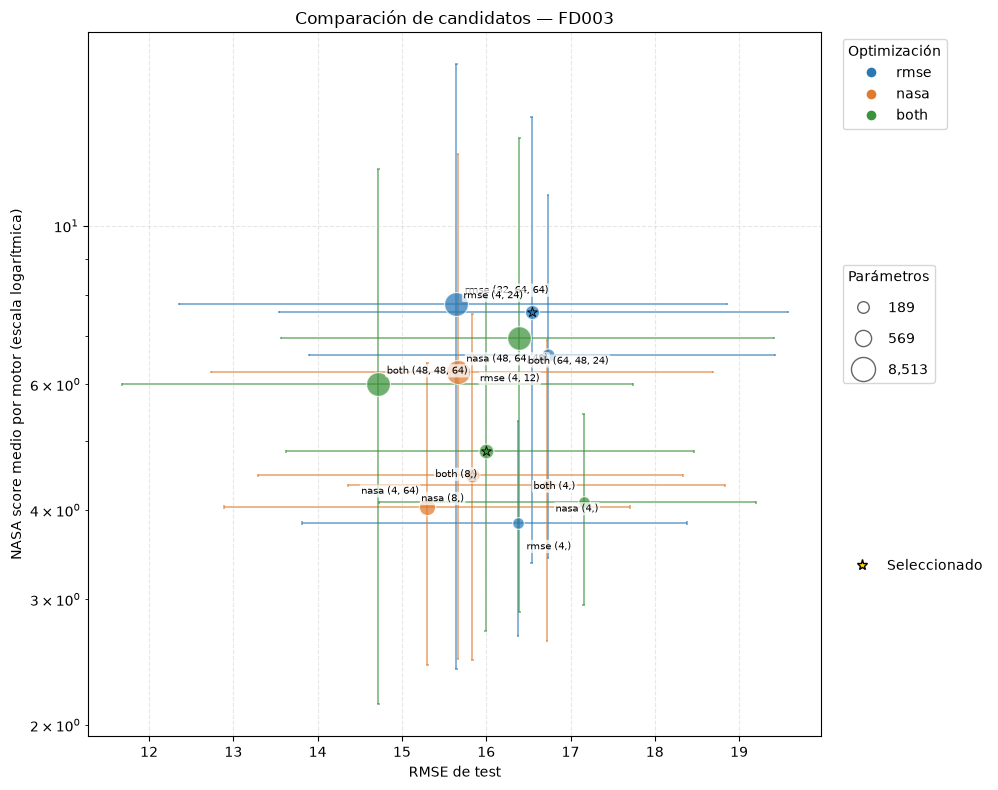

(<Figure size 1300x800 with 1 Axes>,
 <Axes: title={'center': 'Comparación de candidatos — FD003'}, xlabel='RMSE de test', ylabel='NASA score medio por motor (escala logarítmica)'>)

In [43]:
compare_candidate_results('FD001', max_rmse=None, max_nasa=None)

compare_candidate_results('FD003', max_rmse=None, max_nasa=None)

## Distribución de configuraciones candidatas

Las gráficas siguientes muestran, por dataset y función objetivo, cuántos candidatos tienen cada función de activación, función de pérdida y número de capas ocultas.

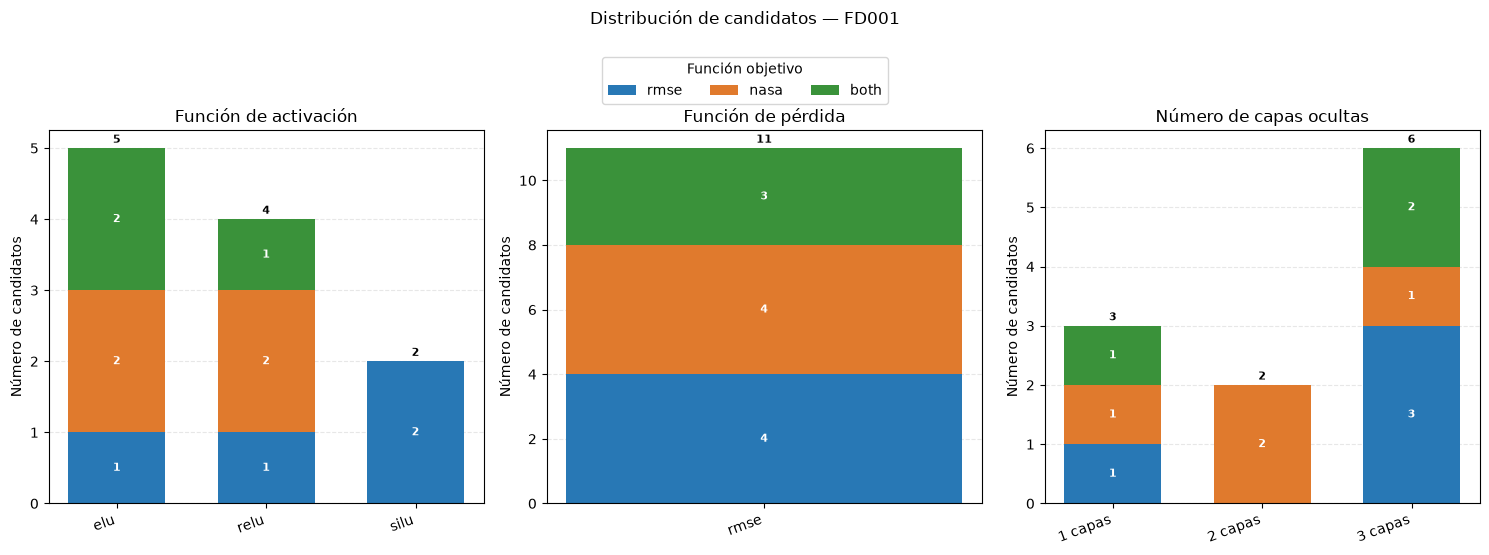

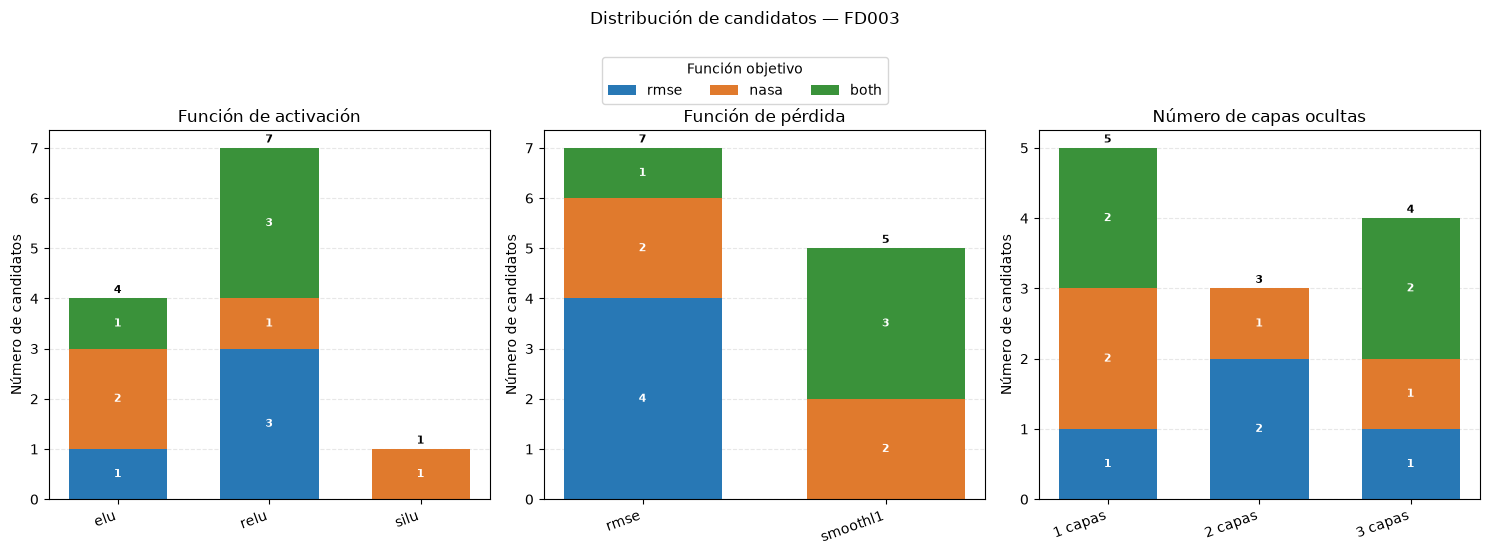

In [44]:
def plot_candidate_configuration_counts(dataset_name, results_dir='mopso_results'):
    """Grafica las frecuencias de activación, pérdida y capas por objetivo."""
    dataset_name = str(dataset_name).strip().upper()
    supported_datasets = {f'FD00{i}' for i in range(1, 5)}
    if dataset_name not in supported_datasets:
        choices = ', '.join(sorted(supported_datasets))
        raise ValueError(
            f'Dataset no admitido: {dataset_name!r}. Use uno de: {choices}.'
        )

    results_dir = Path(results_dir)
    configurations = {objective: [] for objective in OBJECTIVES}
    for objective in OBJECTIVES:
        json_path = results_dir / (
            f'{dataset_name}_mopso_final_candidates_v6_{objective}.json'
        )
        if not json_path.is_file():
            raise FileNotFoundError(f'No se encontró {json_path}.')
        with json_path.open('r', encoding='utf-8') as json_file:
            package = json.load(json_file)
        if package.get('dataset') != dataset_name or package.get('objective') != objective:
            raise ValueError(f'Metadatos inesperados en {json_path}.')
        candidates = package.get('candidates')
        if not isinstance(candidates, list) or not candidates:
            raise ValueError(f'No hay candidatos en {json_path}.')

        for candidate in candidates:
            architecture = candidate.get('architecture', {})
            hidden_sizes = architecture.get('hidden_sizes')
            activation = architecture.get('activation')
            training_loss = architecture.get('training_loss')
            if not isinstance(hidden_sizes, list) or not hidden_sizes:
                raise ValueError(f'Topología oculta inválida en {json_path}.')
            if not activation or not training_loss:
                raise ValueError(f'Falta activación o pérdida en {json_path}.')
            configurations[objective].append({
                'activation': str(activation),
                'training_loss': str(training_loss),
                'hidden_layers': len(hidden_sizes),
            })

    metrics = (
        ('activation', 'Función de activación'),
        ('training_loss', 'Función de pérdida'),
        ('hidden_layers', 'Número de capas ocultas'),
    )
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (metric, title) in zip(axes, metrics):
        categories = sorted({
            candidate[metric]
            for candidates in configurations.values()
            for candidate in candidates
        })
        positions = np.arange(len(categories))
        bottoms = np.zeros(len(categories), dtype=int)
        totals = np.zeros(len(categories), dtype=int)
        for objective in OBJECTIVES:
            counts = {
                category: sum(
                    candidate[metric] == category
                    for candidate in configurations[objective]
                )
                for category in categories
            }
            heights = np.array([counts[category] for category in categories])
            bars = ax.bar(
                positions,
                heights,
                bottom=bottoms,
                width=0.65,
                color=OBJECTIVE_COLORS[objective],
                label=objective,
            )
            ax.bar_label(
                bars,
                labels=[str(value) if value > 0 else '' for value in heights],
                label_type='center',
                color='white',
                fontsize=8,
                fontweight='bold',
            )
            bottoms += heights
            totals += heights
        ax.bar_label(
            ax.containers[-1],
            labels=[str(total) for total in totals],
            label_type='edge',
            padding=2,
            fontsize=8,
            fontweight='bold',
        )

        if metric == 'hidden_layers':
            category_labels = [f'{category} capas' for category in categories]
        else:
            category_labels = [str(category) for category in categories]
        ax.set_xticks(positions, category_labels, rotation=20, ha='right')
        ax.set_title(title)
        ax.set_ylabel('Número de candidatos')
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        ax.set_axisbelow(True)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title='Función objetivo', loc='upper center',
               ncol=len(OBJECTIVES), bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(f'Distribución de candidatos — {dataset_name}', y=1.10)
    fig.tight_layout()
    plt.show()
    return fig, axes


for dataset in ('FD001', 'FD003'):
    plot_candidate_configuration_counts(dataset)